# HMM regimes: do hidden-Markov regime features help the hybrid?

**Step 1 of the HMM study.** A hidden Markov model learns solar-wind regimes and their transition
probabilities from the in-situ data, without hand-made labels (`models.regime_hmm`). Its causal
filter answers "which regime are we in at t0?". The question is whether that answer, given to the
existing models as extra inputs, improves the forecast.

**The model:**
- **States:** 4 hidden states, initialised as slow, intermediate, fast and ejecta from simple thresholds, then fitted by EM (Baum-Welch).
- **Observations each hour,** independent given the state:
  - speed;
  - the log temperature ratio (temperature over the value expected for the speed);
  - log Bt.
- **Two variants:**
  - **ar4:** speed is a per-state AR(1), v_t ~ N(c_s + φ_s v_{t−1}, σ_s²), a Markov-switching autoregression (Hamilton);
  - **level4:** speed is N(m_s, sd_s²) per state, with no autoregression.
- **Features at t0,** from the forward filter at the in-situ row labelled t0 − 1h (the rows are already shifted by the in-situ latency, so only data available at t0 is used):
  - `hmm_p_<state>`: the filtered probability of each state;
  - `hmm_state_hours`: hours since the most probable state last changed.

**Setup** (`python -m training.regime_hmm`):
- **Folds:** the six yearly walk-forward folds (2019-10 → 2025-10). Per fold, the HMM is fitted on the in-situ hours before the fold start, and the shipped linear model and hybrid are refitted with and without the HMM features.
- **Score:** per-run mean TIMSE relative to persistence; the summary is the geometric mean over folds.
- **The eval year is not used.**

| Model | Inputs |
|---|---|
| hybrid | the shipped hybrid (the reference) |
| hybrid + hmm | the hybrid's trees also get the HMM features |
| linear + hmm | the shipped linear model with the HMM features added |
| both + hmm | the hybrid with HMM features, anchored on linear + hmm |

1. Fold scores
2. The learned states
3. The states along the 2024 fold
4. Is the HMM's information already in the hybrid's inputs?
5. Filtering on a live-length window
6. Findings

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from models.regime_hmm import RegimeHMM, observations
from training import pull_features as pf
from training import regime_hmm as rh
from training.datasets import TRAIN_END
from training.xgboost_model import config_path, load_config

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.width", 200)
STATE_COLORS = {"slow": "#2980b9", "intermediate": "#7f8c8d", "fast": "#8e44ad",
                "ejecta": "#c0392b"}

scores = pd.read_csv(rh.EXPERIMENTS / "regime_hmm.csv").set_index("fold")
cached = {p.stem: json.loads(p.read_text(encoding="utf-8"))
          for p in sorted(rh.CACHE_DIR.glob("*.json"))}


def fmt(df, digits=4):
    return df.style.format(precision=digits)


print(f"{len(scores)} folds: {', '.join(scores.index)}")

6 folds: 2019-10, 2020-10, 2021-10, 2022-10, 2023-10, 2024-10


## 1. Fold scores

In [2]:
models = [c for c in scores.columns if c != "seconds"]
geo = {c: float(np.exp(np.log(scores[c]).mean())) for c in models}
summary = pd.DataFrame({
    "fold score": geo,
    "vs hybrid": {c: geo[c] / geo["hybrid"] - 1 for c in models},
    "vs linear": {c: geo[c] / geo["linear"] - 1 for c in models},
    "folds won vs hybrid": {c: int((scores[c] < scores["hybrid"]).sum()) for c in models},
}).sort_values("fold score")
display(summary.style.format({"fold score": "{:.4f}", "vs hybrid": "{:+.1%}",
                              "vs linear": "{:+.1%}"}))
display(fmt(scores[models].T))

,fold score,vs hybrid,vs linear,folds won vs hybrid
hybrid,0.4258,+0.0%,-2.9%,0
both + ar4,0.4263,+0.1%,-2.8%,2
hybrid + level4,0.4265,+0.2%,-2.8%,3
both + level4,0.4272,+0.3%,-2.6%,2
hybrid + ar4,0.4275,+0.4%,-2.6%,3
linear + ar4,0.4372,+2.7%,-0.4%,1
linear,0.4387,+3.0%,+0.0%,0
linear + level4,0.4398,+3.3%,+0.2%,0


fold,2019-10,2020-10,2021-10,2022-10,2023-10,2024-10
linear,0.4292,0.3666,0.5000,0.4648,0.5587,0.3490
hybrid,0.3939,0.3614,0.4921,0.4601,0.5548,0.3331
hybrid + ar4,0.3998,0.3586,0.4898,0.4590,0.5564,0.3404
linear + ar4,0.4282,0.3719,0.4962,0.4631,0.5526,0.3452
both + ar4,0.4000,0.3630,0.4923,0.4590,0.5473,0.3340
hybrid + level4,0.3986,0.3606,0.4938,0.4578,0.5513,0.3358
linear + level4,0.4377,0.3722,0.4953,0.4633,0.5632,0.3438
both + level4,0.4016,0.3697,0.4782,0.4606,0.5489,0.3384


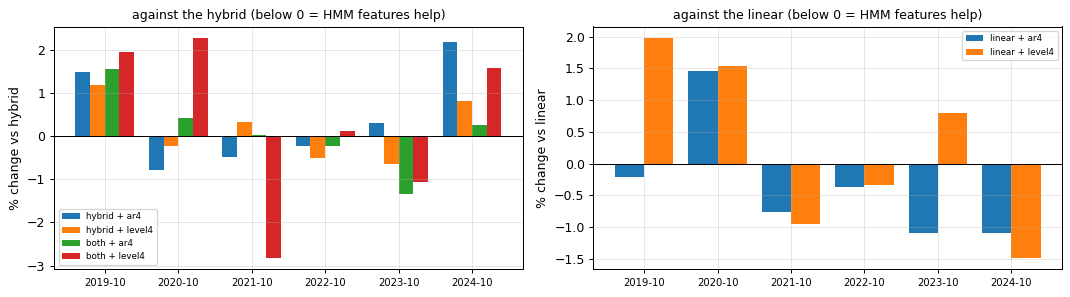

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
x = np.arange(len(scores))
for ax, base, names in ((axes[0], "hybrid", ["hybrid + ar4", "hybrid + level4", "both + ar4",
                                             "both + level4"]),
                        (axes[1], "linear", ["linear + ar4", "linear + level4"])):
    w = 0.8 / len(names)
    for i, n in enumerate(names):
        ax.bar(x + (i - (len(names) - 1) / 2) * w, 100 * (scores[n] / scores[base] - 1), w,
               label=n)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(x, scores.index, fontsize=8)
    ax.set_ylabel(f"% change vs {base}")
    ax.set_title(f"against the {base} (below 0 = HMM features help)", fontsize=10)
    ax.legend(fontsize=7)
fig.tight_layout()

## 2. The learned states

The states fitted before each fold:
- the AR level c/(1 − φ) is where an AR state's speed settles;
- "mean stay" is the expected time in a state before switching, 1 / (1 − P(stay)).

In [4]:
for variant in rh.VARIANTS:
    print(f"\n{variant}: fitted on the hours before 2024-10")
    display(fmt(pd.DataFrame(cached["2024"][f"{variant} states"]), 3))


ar4: fitted on the hours before 2024-10


,speed mean,speed sd,AR level c/(1-phi),AR phi,AR sd,T ratio,Bt (nT),mean stay (h),stationary share
slow,397.011,81.740,294.117,0.984,7.289,1.056,3.457,18.073,0.350
intermediate,429.611,95.594,434.366,0.991,10.577,1.147,5.351,14.378,0.342
fast,445.259,93.671,637.720,0.974,25.688,1.284,8.647,12.857,0.164
ejecta,403.197,76.665,324.879,0.977,7.267,0.810,4.500,11.113,0.144



level4: fitted on the hours before 2024-10


,speed mean,speed sd,AR level c/(1-phi),AR phi,AR sd,T ratio,Bt (nT),mean stay (h),stationary share
slow,333.681,24.677,327.354,0.933,7.529,1.085,3.821,54.486,0.311
intermediate,398.307,40.259,432.966,0.941,13.908,1.149,8.099,22.984,0.203
fast,550.907,66.975,557.615,0.945,20.292,1.075,5.332,50.867,0.234
ejecta,415.548,29.688,395.140,0.930,9.438,1.027,3.928,33.191,0.253


In [5]:
# stability across folds: each state's level and mean stay, fold by fold
rows = []
for year, r in cached.items():
    for variant in rh.VARIANTS:
        s = pd.DataFrame(r[f"{variant} states"])
        level = "AR level c/(1-phi)" if variant == "ar4" else "speed mean"
        for state in s.index:
            rows.append({"fold": f"{year}-10", "variant": variant, "state": state,
                         "level (km/s)": s.loc[state, level],
                         "T ratio": s.loc[state, "T ratio"], "Bt": s.loc[state, "Bt (nT)"],
                         "mean stay (h)": s.loc[state, "mean stay (h)"]})
stab = pd.DataFrame(rows).pivot_table(index=["variant", "state"], columns="fold",
                                      values=["level (km/s)", "mean stay (h)"])
display(fmt(stab, 0))

## 3. The states along the 2024 fold

Both variants are fitted on the hours before 2024-10-20 and filtered through the fold. The top
panel shows the hourly speed coloured by the most probable filtered state; the panels below show
the filtered probabilities. The window is the first three months of the fold.

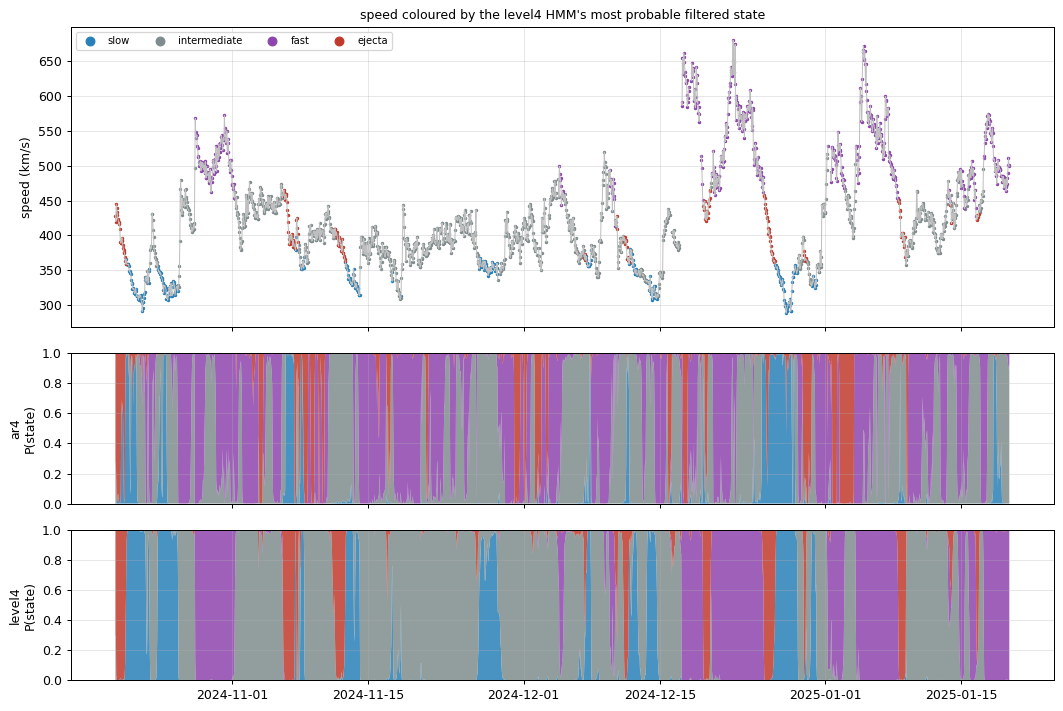

In [6]:
insitu = pf.load_hourly()
insitu = insitu[(insitu.index >= rh.INSITU_START) & (insitu.index < TRAIN_END)]
start = pd.Timestamp("2024-10-20T00:00Z")
fitted = {name: RegimeHMM(cfg).fit(observations(insitu[insitu.index < start]))
          for name, cfg in rh.VARIANTS.items()}
probs = {name: pd.DataFrame(m.filter(observations(insitu)), index=insitu.index,
                            columns=list(m.names)) for name, m in fitted.items()}

window = (insitu.index >= start) & (insitu.index < start + pd.Timedelta(days=92))
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1, 1]})
speed = insitu.loc[window, "speed"]
state = probs["level4"].loc[window].idxmax(axis=1)
axes[0].plot(speed.index, speed, color="0.75", lw=0.8)
for s, color in STATE_COLORS.items():
    sel = state == s
    axes[0].scatter(speed.index[sel], speed[sel], s=3, color=color, label=s)
axes[0].set_ylabel("speed (km/s)")
axes[0].set_title("speed coloured by the level4 HMM's most probable filtered state", fontsize=10)
axes[0].legend(ncol=4, fontsize=8, markerscale=4)
for ax, name in zip(axes[1:], rh.VARIANTS, strict=True):
    p = probs[name].loc[window]
    ax.stackplot(p.index, p.T.to_numpy(), colors=[STATE_COLORS[c] for c in p.columns],
                 alpha=0.85)
    ax.set_ylabel(f"{name}\nP(state)")
    ax.set_ylim(0, 1)
fig.tight_layout()

**Do the states match physical conditions?** For each most probable filtered state (fitted
before 2024-10, filtered over the 2024 fold):
- the share of hours in each current speed band;
- the share flagged as ejecta-like (cold, with field ≥ 8 nT: the in-situ `icme` flag);
- the median hours spent in the state per visit.

In [7]:
fold = (insitu.index >= start)
band = pd.cut(insitu.loc[fold, "speed"], [0, 400, 550, 2000],
              labels=["< 400", "400-550", ">= 550"])
rows = {}
for name in rh.VARIANTS:
    st = probs[name].loc[fold].idxmax(axis=1)
    tab = pd.crosstab(st, band, normalize="index")
    tab["icme-flagged share"] = insitu.loc[fold, "icme"].groupby(st).mean()
    tab["share of hours"] = st.value_counts(normalize=True)
    visits = (st != st.shift()).cumsum()
    tab["median visit (h)"] = st.groupby(visits).agg(["first", "size"]).groupby("first")[
        "size"].median()
    rows[name] = tab
display(fmt(pd.concat(rows), 3))

## 4. Is the HMM's information already in the hybrid's inputs?

If the hybrid's existing inputs can reproduce the HMM features, the trees gain nothing from them.
Each HMM feature at t0 is predicted from the hybrid's inputs:
- the 30 regressors;
- the last speed;
- the 27-day and 13.5-day recurrence means.

The predictor is gradient-boosted trees, fitted on hourly t0s before 2024-10 and scored (R²) on
the 2024 fold.

In [8]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score

from feature_engineering.recurrence import LEADS, last_observed, window_means
from training import compare_history as ch

data = ch.Data()
cfg = load_config(config_path("linear"))
t0s = data.hourly
pos = data.series.index.get_indexer(t0s)
x = [data.table.loc[t0s, list(cfg.features)].to_numpy(dtype=float),
     last_observed(data.values, pos)[:, None]]
for lag in cfg.lag_hours:
    with np.errstate(invalid="ignore"):
        x.append(np.nanmean(window_means(data.values, pos[:, None] + LEADS - lag,
                                         cfg.half_width), axis=1)[:, None])
x = np.hstack(x)
train = np.asarray(t0s < start)
rng = np.random.default_rng(0)
fit_rows = rng.choice(np.flatnonzero(train), 20000, replace=False)
val_rows = np.flatnonzero(~train)
r2 = {}
for name, m in fitted.items():
    feats = m.features(insitu, t0s)
    for col in feats.columns:
        y = feats[col].to_numpy()
        ok_fit = fit_rows[np.isfinite(y[fit_rows])]
        ok_val = val_rows[np.isfinite(y[val_rows])]
        model = HistGradientBoostingRegressor(max_iter=200, random_state=0).fit(
            x[ok_fit], y[ok_fit])
        r2[(name, col)] = r2_score(y[ok_val], model.predict(x[ok_val]))
display(fmt(pd.Series(r2, name="R² on the 2024 fold").to_frame(), 3))

C:\Users\ching\AppData\Local\Temp\ipykernel_14716\436808625.py:15: RuntimeWarning: Mean of empty slice
  x.append(np.nanmean(window_means(data.values, pos[:, None] + LEADS - lag,


## 5. Filtering on a live-length window

Live, the forecast fetches about 3 months of in-situ history, so the filter would start from the
stationary distribution 90 days before t0 instead of in 2016. Comparing the two on 200 random
2024-fold t0s shows whether the features would match those used in training.

In [9]:
m = fitted["level4"]
full = m.features(insitu, t0s)
sample = rng.choice(t0s[t0s >= start], 200, replace=False)
diffs = []
for t0 in sample:
    recent = insitu[(insitu.index >= t0 - pd.Timedelta(days=90)) & (insitu.index < t0)]
    live = m.features(recent, pd.DatetimeIndex([t0]))
    diffs.append((live.iloc[0] - full.loc[t0]).abs())
diffs = pd.DataFrame(diffs)
display(fmt(diffs.describe().loc[["mean", "50%", "max"]], 4))

,hmm_p_slow,hmm_p_intermediate,hmm_p_fast,hmm_p_ejecta,hmm_state_hours
mean,0.0000,0.0000,0.0000,0.0000,0.0000
50%,0.0000,0.0000,0.0000,0.0000,0.0000
max,0.0000,0.0000,0.0000,0.0000,0.0000


## 6. Findings

### Verdict: HMM regime features don't help; step 2 (regressor-driven transitions) is not pursued

| Six-fold score | Score | vs hybrid | Folds won |
|---|---|---|---|
| hybrid (the reference) | 0.4258 | | |
| both + ar4 | 0.4263 | +0.1% | 2 |
| hybrid + level4 | 0.4265 | +0.2% | 3 |
| hybrid + ar4 | 0.4275 | +0.4% | 3 |
| linear + ar4 | 0.4372 | −0.3% vs the linear model | |

Every variant is within noise of the hybrid, and the per-fold differences go both ways. The only
gain is −0.3% on the linear model alone (ar4), which can't use its inputs nonlinearly; the level4
variant makes the linear model slightly worse.

### (i) The states: sensible speed levels, no CME state

- **level4 is stable across folds.** Fitted before each fold, it finds:
  - slow, about 335 km/s, mean stay about 2.5 days;
  - fast, about 555 km/s, about 2 days;
  - two intermediate states, 400–445 km/s, one of them with a stronger field.
- **ar4 is not stable.** Its states separate mainly by volatility (AR noise of 7–26 km/s/h), not by level. Their meaning swaps between folds: in 2019 the "intermediate" state settles at 950 km/s. They last about half a day.
- **Neither has a CME state.** CMEs are too rare (about 10% of hours) and too varied for unsupervised EM to give them their own state.
  - The best candidate, ar4's cold state, is flagged as ejecta-like in only 17% of its hours in the 2024 fold.
  - level4's "ejecta" state is just another intermediate state.
- **In the 2024 fold (solar maximum),** level4's slow state, learned mostly on quieter years, covers only 8% of hours.

### (ii) The HMM's information is already in the hybrid's inputs

Gradient-boosted trees on the hybrid's own inputs predict the filtered state probabilities with:
- R² 0.86–0.93 for level4;
- R² 0.71–0.83 for ar4.

The filter is a smoothed function of recent speed, temperature ratio and Bt, which the hybrid
already sees (last speed, `bt_mean_1h`, `log_t_ratio_mean_1h`, `speed_mean_24h`…). The one feature
the inputs can't reproduce, hours in the current state (R² ≈ 0.03), doesn't help either.

### (iii) Live readiness, for the record

Filtered on a 90-day window (the live history length), the features match the full-history filter to
3 decimals on 200 random t0s. The model is numpy only and fits in 15–30 s, so it could run live if a
later model needs it.

### What this means

1. **A regime filter with fixed transitions adds nothing over the hybrid's inputs.**
2. **Step 2 is not pursued.** Regressor-driven transitions would put coronal-hole area and the recurrence terms into the switch probabilities, but the hybrid already uses both as inputs, so step 1 gives no reason to expect a gain.
3. **Together with the regime-routing study** (`regime_models.ipynb`), regime structure doesn't look like the missing ingredient. The remaining errors are onsets (stream arrivals, CMEs) that the t0 inputs don't foresee, and the quiet-wind level at 72 h.

### Caveats

- **The settings were fixed, not tuned:** 4 states and the two variants. More states, or emissions with density or field variability, were not tried.
- **The HMM is fitted by likelihood, not TIMSE.**
- **The eval year was not used.**